In [7]:
from sklearn import datasets
import pandas as pd

In [13]:
data_obj = datasets.load_breast_cancer()

# 2. Create the DataFrame using the data and the feature names
df = pd.DataFrame(data_obj.data, columns=data_obj.feature_names)

# 3. Add the target (the 0 or 1 labels) as a new column
df['target'] = data_obj.target

df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [14]:
print(df['target'].value_counts())

target
1    357
0    212
Name: count, dtype: int64


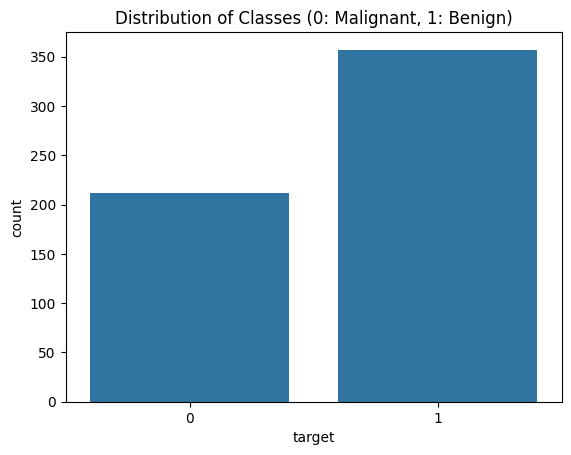

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='target', data=df)
plt.title('Distribution of Classes (0: Malignant, 1: Benign)')
plt.show()

In [20]:
x = df.drop('target', axis=1)
y = df['target']


In [23]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
from imblearn.over_sampling import SMOTE
import collections

# 1. Initialize SMOTE
# sampling_strategy=1.0 will make the number of 0s equal to the number of 1s
# If you want exactly 300, you can pass a specific dictionary
smote = SMOTE(random_state=42)

# 2. Resample the training data
x_train_res, y_train_res = smote.fit_resample(x_train, y_train)

# 3. Check the new counts
print(f"Original dataset shape: {collections.Counter(y_train)}")
print(f"Resampled dataset shape: {collections.Counter(y_train_res)}")


Original dataset shape: Counter({1: 286, 0: 169})
Resampled dataset shape: Counter({1: 286, 0: 286})


/var/folders/jc/7x43gzsd0ybf2zmkdszbzbjm0000gn/T/ipykernel_88535/4218841494.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df_resampled, palette='viridis')


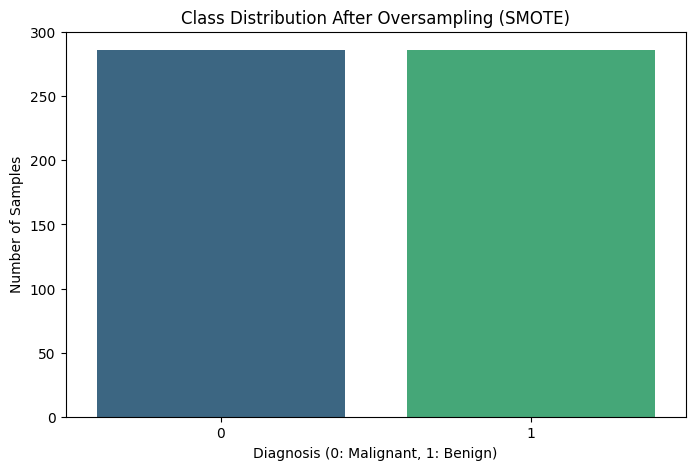

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Create a temporary DataFrame for the new labels
df_resampled = pd.DataFrame(y_train_res, columns=['target'])

# Plotting
plt.figure(figsize=(8, 5))
sns.countplot(x='target', data=df_resampled, palette='viridis')

# Add labels and title
plt.title('Class Distribution After Oversampling (SMOTE)')
plt.xlabel('Diagnosis (0: Malignant, 1: Benign)')
plt.ylabel('Number of Samples')


plt.show()

/var/folders/jc/7x43gzsd0ybf2zmkdszbzbjm0000gn/T/ipykernel_88535/2980320034.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, ax=ax[0], palette='magma')
/var/folders/jc/7x43gzsd0ybf2zmkdszbzbjm0000gn/T/ipykernel_88535/2980320034.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_res, ax=ax[1], palette='viridis')


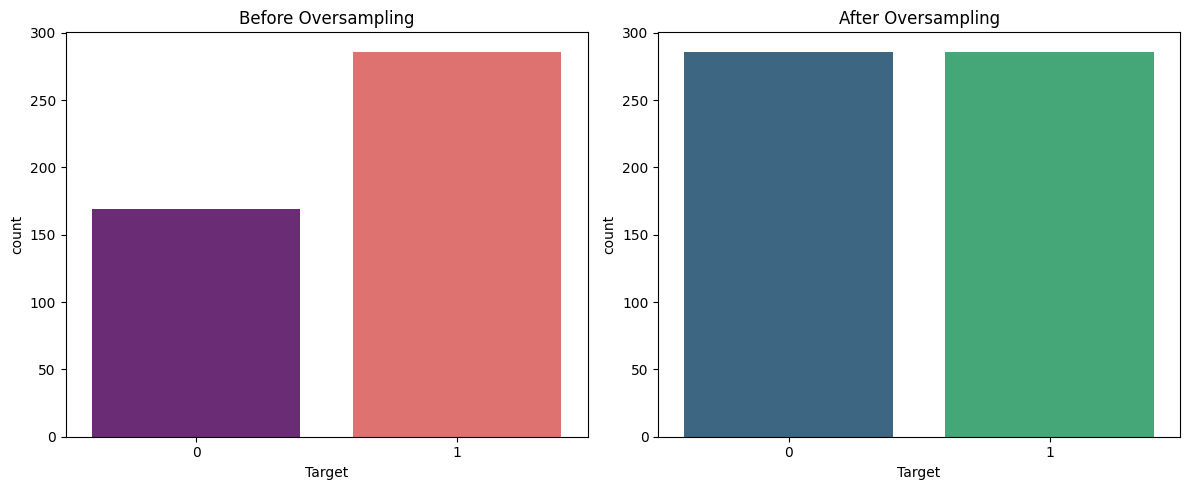

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
sns.countplot(x=y_train, ax=ax[0], palette='magma')
ax[0].set_title('Before Oversampling')
ax[0].set_xlabel('Target')

# After SMOTE
sns.countplot(x=y_train_res, ax=ax[1], palette='viridis')
ax[1].set_title('After Oversampling')
ax[1].set_xlabel('Target')

plt.tight_layout()
plt.show()